# Compress와 Isolate

**이 노트북에서 할 일**

1. 도서관 안내 원문을 줄인 기록으로 옮기고, 꼭 남길 말이 남았는지 코드로 확인합니다.
2. 대출 업무와 휴관 업무의 메시지 목록을 따로 만들어, 다른 업무의 기록이 섞이지 않았는지 봅니다.
3. 조건이 빠진 줄인 기록(Before)과 조건을 남긴 줄인 기록(After)으로 같은 질문을 보내 답을 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 원문과 기록은 셀 안에 적고, 파일은 만들지 않습니다.

인터넷 서비스에 요청을 모두 3번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3·4·6절(Compress, Isolate, Before)을 설명합니다.
5·7절(값 바꿔 보기, After)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

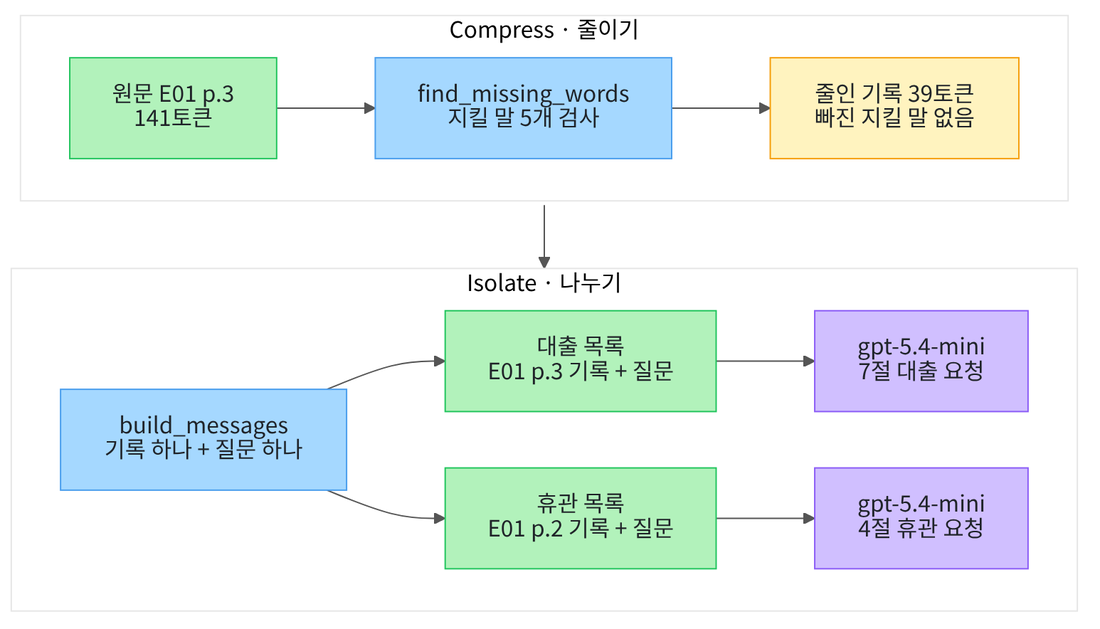

위 칸이 줄이기(Compress), 아래 칸이 나누기(Isolate)입니다. 칸마다 왼쪽에서 오른쪽으로 읽습니다.
초록 상자는 원문과 메시지 목록, 파란 상자는 노트북 코드의 단계입니다. 노란 상자는 출력으로 확인한 검사 결과, 보라 상자는 모델입니다.
원문을 줄인 기록은 업무마다 따로 만든 목록에 들어가고, 목록 하나가 요청 하나로 갑니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01·02절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

토큰 수를 세는 라이브러리와 모델 함수를 불러옵니다. 이 절은 파일을 쓰지 않아 모듈 `json`·`tempfile`은 부르지 않습니다.

In [2]:
# 토큰 수를 세는 라이브러리와 모델 함수를 불러옵니다
import tiktoken

from langchain.chat_models import init_chat_model

01·02절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


## 2. 02절에서 이어 쓰는 글과 수업 예산표

페르소나와 과업 명세는 02절과 글자까지 같습니다. 과업 명세는 문장마다 끝에 출처 표시를 적게 합니다.
출처 표시 `[E01 p.2]`는 모양을 보여 주는 예입니다.

In [4]:
# 02절과 같은 페르소나와 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에 `문장마다 끝에 출처를`이 있습니다.

수업 예산표도 01·02절과 같은 값으로 이어 씁니다. 수업 예산 600에서 출력 예약분 120과 여유분 40을 먼저 뗍니다.
먼저 01절과 같은 뺄셈 함수를 정의합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [5]:
# 수업 예산에서 출력 예약분과 여유분을 빼, 입력에 쓸 수 있는 토큰 수를 반환하는 함수를 정의합니다
def input_budget(total_budget, output_reserve, safety_margin):
    available = total_budget - output_reserve - safety_margin
    return available

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

세 값을 01·02절과 같게 담고 입력 가용분을 구합니다.
실행 전에 예상합니다. 01·02절처럼 440일 것입니다.

In [6]:
# 01·02절과 같은 수업 예산·출력 예약분·여유분으로 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
이 절에서 만드는 메시지 목록도 모두 입력 가용분 440 안에 들어야 합니다.

요청 전에 토큰 수를 셀 함수도 01·02절과 같은 코드로 정의합니다.
함수 `tiktoken.encoding_for_model()`은 모델 이름을 받아 토큰화 규칙 객체를 반환합니다.
함수 `count_tokens()`는 이 규칙 객체 `encoding`을 읽어 글 하나의 토큰 수를 반환합니다. 이 셀은 출력이 없습니다.

In [7]:
# 01·02절처럼 모델의 토큰화 규칙을 불러오고, 글 하나의 토큰 수를 반환하는 함수를 정의합니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")


def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 규칙 객체를 만들고 함수를 정의만 하는 셀이라 출력이 없습니다.

모델 객체는 02절처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.
마지막 줄 `assert`는 예산표의 출력 예약분이 모델 설정에 그대로 들어갔는지 확인합니다.

In [8]:
# 출력 예약분을 출력 상한으로 준 모델을 준비합니다(02절과 같은 설정)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)
assert model.max_tokens == output_reserve

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): 120`입니다. `assert`도 통과했습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 3. Compress — 원문을 줄이고 지킬 말 확인하기

02절 대출 기록의 내용은 E01 3쪽 원문을 한 문장으로 옮겨 적은 것이었습니다.
이번에는 그 원문을 직접 보고, 조건을 남기며 줄입니다.

줄이기(Compress)는 원문의 표현을 줄여 토큰 수를 줄이되, 답에 필요한 사실과 조건은 남기는 일입니다.
긴 공지문을 친구에게 문자로 옮길 때 날짜와 「단, …」 조건은 빼지 않는 것과 비슷합니다.

먼저 E01 3쪽 「4. 자료 대출」 원문 세 문단을 변수에 담습니다. 01절처럼 같은 이름에 글을 `+`로 이어 다시 담습니다.
실행 전에 예상합니다. 원문은 제목 줄과 다섯 문장이라 100토큰을 넘을 것입니다.

In [9]:
# E01 3쪽 「4. 자료 대출」 원문 세 문단을 담고, 글자 수와 토큰 수를 셉니다
loan_original = "[E01 p.3] 4. 자료 대출\n"
loan_original = loan_original + "회원 한 사람이 한 번에 빌릴 수 있는 자료는 도서 7권과 영상 자료 2점입니다. "
loan_original = loan_original + "대출 기간은 도서 14일, 영상 자료 7일입니다.\n"
loan_original = loan_original + "대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있습니다. "
loan_original = loan_original + "연장은 반납 예정일 전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다.\n"
loan_original = loan_original + "정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내에서만 열람할 수 있고 대출되지 않습니다."
print("원문:")
print(loan_original)
print("원문 글자 수:", len(loan_original))
print("원문 토큰 수:", count_tokens(loan_original))

원문:
[E01 p.3] 4. 자료 대출
회원 한 사람이 한 번에 빌릴 수 있는 자료는 도서 7권과 영상 자료 2점입니다. 대출 기간은 도서 14일, 영상 자료 7일입니다.
대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있습니다. 연장은 반납 예정일 전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다.
정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내에서만 열람할 수 있고 대출되지 않습니다.
원문 글자 수: 243
원문 토큰 수: 141


**결과 읽기** — 라벨 줄 `원문:` 아래에 네 줄이 나옵니다. 둘째 줄이 권수와 기간, 셋째 줄이 연장 조건입니다.
마지막 두 줄은 `원문 글자 수: 243`과 `원문 토큰 수: 141`입니다.

이 절의 대출 업무 질문은 빌린 도서의 대출 기간을 연장할 수 있는지 묻습니다.
이 질문에 답하려고 원문에서 꼭 남길 말을 사람이 고릅니다. 이 목록을 지킬 말이라고 부르겠습니다.
지킬 말에는 사실(권수·기간)과 조건(예약이 없는 경우·1회·7일 연장)을 함께 넣었습니다.

In [10]:
# 대출 업무의 질문과, 원문을 줄여도 꼭 남길 지킬 말 목록을 정합니다
loan_question = "미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?"
keep_words = ["7권", "14일", "예약이 없는 경우", "1회", "7일 연장"]
print("질문:", loan_question)
print("지킬 말:", keep_words)

질문: 미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?
지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']


**결과 읽기** — 출력 줄은 `질문:` 줄과 `지킬 말: ['7권', '14일', '예약이 없는 경우', '1회', '7일 연장']`입니다.
영상 자료, 연장 신청 방법, 대출되지 않는 자료는 이번 질문의 지킬 말로 고르지 않았습니다.
질문이 「연장은 어떻게 신청하나요?」로 바뀌면 지킬 말도 다시 골라야 합니다.

글 하나와 지킬 말 목록을 받아, 글에 없는 말만 목록으로 반환하는 함수를 정의합니다.
Ch 7 01절 확인 단어처럼 `in`으로 글 안에 그 말이 있는지 봅니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [11]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

먼저 원문과 02절 대출 기록을 검사합니다. 원문에는 지킬 말이 모두 있어야 합니다.
실행 전에 예상합니다. 02절 기록에는 연장 이야기가 없으니 조건 쪽 말이 빠졌을 것입니다.

In [12]:
# 원문과 02절 대출 기록에서 빠진 지킬 말을 찾습니다
note_02_text = "도서는 7권까지 14일 동안 대출할 수 있습니다."
original_missing = find_missing_words(loan_original, keep_words)
note_02_missing = find_missing_words(note_02_text, keep_words)
print("원문에서 빠진 지킬 말:", original_missing)
print("02절 대출 기록에서 빠진 지킬 말:", note_02_missing)
print("02절 대출 기록 토큰 수:", count_tokens(note_02_text))

원문에서 빠진 지킬 말: []
02절 대출 기록에서 빠진 지킬 말: ['예약이 없는 경우', '1회', '7일 연장']
02절 대출 기록 토큰 수: 16


**결과 읽기** — 출력 줄은 `원문에서 빠진 지킬 말: []`과 `02절 대출 기록에서 빠진 지킬 말: ['예약이 없는 경우', '1회', '7일 연장']`입니다.
마지막 줄은 `02절 대출 기록 토큰 수: 16`입니다.
02절 기록은 권수를 묻는 02절 질문에는 충분했지만, 연장을 묻는 이번 질문에 필요한 조건은 모두 빠졌습니다.

이제 지킬 말을 모두 남기며 원문을 줄인 기록을 만듭니다. 키는 02절 기록과 같은 `출처`·`기관`·`주제`·`내용`입니다.
사람이 원문을 읽고 줄여 적은 이 기록을 줄인 기록이라고 부르겠습니다. 모델에게 줄이게 한 것이 아닙니다.

실행 전에 예상합니다. 빠진 지킬 말은 없고, 토큰 수는 원문 141보다 적을 것입니다.

In [13]:
# 지킬 말을 모두 남긴 줄인 기록을 만들고, 빠진 말과 토큰 수를 확인합니다
loan_note = {
    "출처": "E01 p.3",
    "기관": "미르시립도서관",
    "주제": "대출",
    "내용": "회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다.",
}
loan_missing = find_missing_words(loan_note["내용"], keep_words)
print("줄인 기록에서 빠진 지킬 말:", loan_missing)
print("줄인 기록 글자 수:", len(loan_note["내용"]))
print("줄인 기록 토큰 수:", count_tokens(loan_note["내용"]))
assert loan_missing == []

줄인 기록에서 빠진 지킬 말: []
줄인 기록 글자 수: 66
줄인 기록 토큰 수: 39


**결과 읽기** — 출력 줄은 `줄인 기록에서 빠진 지킬 말: []`, `줄인 기록 글자 수: 66`, `줄인 기록 토큰 수: 39`입니다. `assert`도 통과했습니다.
원문 141토큰이 39토큰으로 줄었습니다. 영상 자료와 신청 방법처럼 지킬 말이 아닌 내용은 뺐습니다.

지킬 말 검사는 목록에 적은 말이 글에 들어 있는지만 봅니다. 줄인 기록의 뜻이 원문과 같은지는 사람이 원문과 나란히 놓고 읽어 확인합니다.
지킬 말 목록에 적지 않은 조건이 빠지면 검사는 알려 주지 않습니다.

## 4. Isolate — 업무마다 메시지 목록 나누기

나누기(Isolate)는 서로 다른 업무의 자료를 한 메시지 목록에 섞지 않고, 업무마다 목록을 따로 만들어 보내는 일입니다.
두 과목 숙제를 과목별 공책에 따로 적는 것과 비슷합니다.
이 노트북의 업무는 둘입니다. 3절의 대출 연장 안내와, 01절에서 다룬 휴관 안내입니다.

휴관 업무의 기록도 같은 방법으로 줄입니다. 01절 근거 문단(E01 2쪽)에서 지킬 말 셋을 정하고, 조건을 남긴 기록을 만듭니다.
질문은 01절 질문과 글자까지 같습니다.

In [14]:
# 휴관 업무의 줄인 기록·질문·지킬 말을 만들고, 빠진 말과 토큰 수를 확인합니다
closure_note = {
    "출처": "E01 p.2",
    "기관": "미르시립도서관",
    "주제": "휴관",
    "내용": "매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.",
}
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
closure_missing = find_missing_words(closure_note["내용"], closure_keep_words)
print("휴관 기록에서 빠진 지킬 말:", closure_missing)
print("휴관 기록 토큰 수:", count_tokens(closure_note["내용"]))

휴관 기록에서 빠진 지킬 말: []
휴관 기록 토큰 수: 40


**결과 읽기** — 출력 줄은 `휴관 기록에서 빠진 지킬 말: []`과 `휴관 기록 토큰 수: 40`입니다.
01절 원문의 「법정 공휴일에도 휴관」과 「그 다음 날인 화요일」 조건이 줄인 기록에 남았습니다.

업무 하나의 기록과 질문을 받아 메시지 목록을 만드는 함수를 정의합니다. 목록 모양은 02절과 같은 system·developer·user 세 메시지입니다.
user 글은 출처 표시를 붙인 기록 한 줄, 빈 줄, 질문 순서입니다.
함수는 Ch 5에서 본 것처럼 바깥 이름 `persona_text`와 `task_text`를 읽습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 기록 하나와 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다
def build_messages(note, question):
    user_text = "[" + note["출처"] + "] " + note["내용"] + "\n\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

같은 함수로 대출 목록과 휴관 목록을 따로 만듭니다. 목록의 셋째 메시지에서 user 글을 꺼내 다른 업무의 출처 표시가 있는지 봅니다.

인덱스 `loan_messages[2][1]`은 셋째 튜플의 둘째 값, 곧 user 글입니다. Ch 7 01절에서 쓴 인덱스 두 번 모양입니다.
실행 전에 예상합니다. 두 목록 모두 다른 업무의 출처가 없을 것입니다.

In [16]:
# 대출 업무와 휴관 업무의 메시지 목록을 따로 만들고, 다른 업무의 출처가 섞였는지 봅니다
loan_messages = build_messages(loan_note, loan_question)
closure_messages = build_messages(closure_note, closure_question)
loan_user_text = loan_messages[2][1]
closure_user_text = closure_messages[2][1]
print("대출 목록 user 글:")
print(loan_user_text)
print("대출 목록에 휴관 출처가 있는가:", "[E01 p.2]" in loan_user_text)
print("휴관 목록에 대출 출처가 있는가:", "[E01 p.3]" in closure_user_text)

대출 목록 user 글:
[E01 p.3] 회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다.

질문: 미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?
대출 목록에 휴관 출처가 있는가: False
휴관 목록에 대출 출처가 있는가: False


**결과 읽기** — 라벨 줄 `대출 목록 user 글:` 아래 첫 줄은 `[E01 p.3] 회원 한 사람의 도서 대출 기준은`으로 시작합니다. 빈 줄 다음은 `질문:` 줄입니다.
마지막 두 줄은 `대출 목록에 휴관 출처가 있는가: False`와 `휴관 목록에 대출 출처가 있는가: False`입니다.
어느 기록을 어느 목록에 넣을지는 사람이 코드에 정했습니다. 모델이 업무를 나눈 것이 아닙니다.

두 목록의 추정 입력을 01절 예산표처럼 셉니다. 페르소나와 과업 명세는 두 목록에 똑같이 들어가므로 한 번 세어 변수에 담습니다.
실행 전에 예상합니다. 짧은 기록 한 줄씩이라 두 목록 모두 440 안에 들어갈 것입니다.

In [17]:
# 두 목록의 추정 입력을 세어 입력 가용분과 비교합니다(요청은 보내지 않습니다)
shared_tokens = count_tokens(persona_text) + count_tokens(task_text)
loan_estimate = shared_tokens + count_tokens(loan_user_text)
closure_estimate = shared_tokens + count_tokens(closure_user_text)
print("페르소나 + 과업 명세 토큰 수:", shared_tokens)
print("대출 목록 추정 입력 합계:", loan_estimate)
print("휴관 목록 추정 입력 합계:", closure_estimate)
print("대출 목록이 입력 가용분 안에 드는가:", loan_estimate <= available)
print("휴관 목록이 입력 가용분 안에 드는가:", closure_estimate <= available)

페르소나 + 과업 명세 토큰 수: 55
대출 목록 추정 입력 합계: 128
휴관 목록 추정 입력 합계: 136
대출 목록이 입력 가용분 안에 드는가: True
휴관 목록이 입력 가용분 안에 드는가: True


**결과 읽기** — 출력 줄은 `페르소나 + 과업 명세 토큰 수: 55`, `대출 목록 추정 입력 합계: 128`, `휴관 목록 추정 입력 합계: 136`입니다.
마지막 두 줄은 모두 `True`입니다. 두 목록은 따로 보내므로 요청마다 입력 가용분 440과 비교합니다.

휴관 목록을 먼저 보냅니다. 대출 목록은 7절 After에서 보냅니다. 요청 하나에는 목록 하나만 넣습니다.
답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.

실행 전에 예상합니다. 답에는 휴관 기록의 출처 표시만 붙을 것입니다.

In [18]:
# 휴관 목록 하나만 보냅니다(요청 1번)
closure_response = model.invoke(closure_messages)
print("답:")
print(closure_response.text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.`입니다. 두 문장 끝에 모두 `[E01 p.2]`가 붙었습니다.

휴관 기록에 남긴 두 조건이 답에 모두 들어갔습니다. 실행마다 답 문장이 달라질 수 있습니다.

답에 적힌 출처 표시로 기록을 되짚으려고, 02절 함수 `find_cited_notes()`를 같은 코드로 정의합니다.
이 함수는 답 글과 기록 목록을 받아, 출처 표시가 답 글에 들어 있는 기록만 목록으로 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [19]:
# 답 글에 출처 표시가 들어 있는 기록만 골라 반환하는 함수를 정의합니다(02절과 같은 코드)
def find_cited_notes(answer_text, notes):
    cited = []
    for note in notes:
        mark = "[" + note["출처"] + "]"
        if mark in answer_text:
            cited.append(note)
    return cited

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

휴관 답의 토큰 수와 끝난 이유를 보고, 답에 적힌 출처 표시를 두 줄인 기록에서 찾습니다.
찾은 기록은 출처만 모아 한 줄로 출력합니다. 반복문 안에서는 `append`만 합니다.

In [20]:
# 휴관 답의 토큰 수와 끝난 이유를 보고, 답에 적힌 출처를 두 기록에서 찾습니다
closure_usage = closure_response.usage_metadata
print("실제 입력 토큰 수:", closure_usage["input_tokens"])
print("실제 출력 토큰 수:", closure_usage["output_tokens"])
print("끝난 이유:", closure_response.response_metadata["finish_reason"])
all_notes = [loan_note, closure_note]
closure_cited = find_cited_notes(closure_response.text, all_notes)
cited_sources = []
for note in closure_cited:
    cited_sources.append(note["출처"])
print("답의 출처 표시와 같은 기록:", cited_sources)

실제 입력 토큰 수: 150
실제 출력 토큰 수: 66
끝난 이유: stop
답의 출처 표시와 같은 기록: ['E01 p.2']


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 150`, `실제 출력 토큰 수: 66`, `끝난 이유: stop`입니다.
마지막 줄은 `답의 출처 표시와 같은 기록: ['E01 p.2']`입니다. 두 기록 가운데 휴관 기록 하나만 찾았습니다.

이 요청에는 휴관 기록만 실렸으므로, 답이 대출 기록을 쓸 수 없었습니다. 추정 136과 실제 150의 차이는 14로, 01·02절과 같은 값이었습니다.

## 5. 값 바꿔 보기 — 두 업무를 한 목록에 함께 넣으면

바꾸는 것은 목록을 나누는지 하나뿐입니다. 두 줄인 기록과 두 질문을 user 글 하나에 함께 넣습니다.
기록과 질문의 글자는 4절과 같습니다. 이 셀은 글을 만들고 세기만 하고, 요청은 보내지 않습니다.

실행 전에 예상합니다. 한 목록에는 두 출처가 모두 들어갑니다.
페르소나와 과업 명세를 한 번만 넣으니, 추정 입력은 나눈 두 목록의 합보다 작을 것입니다.

In [21]:
# 두 업무의 기록과 질문을 user 글 하나에 함께 넣고, 나눈 두 목록과 비교합니다(요청은 보내지 않습니다)
mixed_user_text = "[E01 p.3] " + loan_note["내용"] + "\n"
mixed_user_text = mixed_user_text + "[E01 p.2] " + closure_note["내용"] + "\n\n"
mixed_user_text = mixed_user_text + "질문 1: " + loan_question + "\n"
mixed_user_text = mixed_user_text + "질문 2: " + closure_question
mixed_estimate = shared_tokens + count_tokens(mixed_user_text)
separated_total = loan_estimate + closure_estimate
has_both_sources = "[E01 p.3]" in mixed_user_text and "[E01 p.2]" in mixed_user_text
print("한 목록에 두 출처가 모두 있는가:", has_both_sources)
print("한 목록 추정 입력 합계:", mixed_estimate)
print("나눈 두 목록 추정 입력의 합:", separated_total)

한 목록에 두 출처가 모두 있는가: True
한 목록 추정 입력 합계: 213
나눈 두 목록 추정 입력의 합: 264


**결과 읽기** — 출력 줄은 `한 목록에 두 출처가 모두 있는가: True`, `한 목록 추정 입력 합계: 213`, `나눈 두 목록 추정 입력의 합: 264`입니다.
나눈 두 목록에는 페르소나와 과업 명세 55토큰이 한 번 더 들어가, 두 요청을 합한 추정 입력이 51토큰 많습니다.

이번 예에서 나누기는 전체 토큰을 줄이지 않았습니다. 나누기로 얻은 것은 요청마다 그 업무의 기록만 모델에 간다는 점입니다.
한 목록으로 보내면 대출 질문에 답할 때도 휴관 기록이 함께 모델에 갑니다. 과업 명세의 「두 문장 이내」도 질문 두 개와 맞지 않습니다.
이 목록을 보냈을 때 답이 어떻게 달라지는지는 이번에 실행하지 않았습니다.

## 6. Before — 조건이 빠진 줄인 기록으로 답하기

원문을 줄이다가 조건을 빼먹은 경우를 봅니다. 3절 줄인 기록을 복사해 키 `내용`만 바꿉니다.
「다른 이용자의 예약이 없는 경우에만」을 뺐고, 나머지 글자는 같습니다.
메서드 `copy()`는 Ch 2에서 배운 대로 딕셔너리를 복사합니다. 복사본을 고쳐도 `loan_note`는 그대로입니다.

실행 전에 예상합니다. 지킬 말 검사가 빠진 말 하나를 찾아낼 것입니다.

In [22]:
# 조건을 뺀 줄인 기록으로 대출 목록을 만들고, 빠진 지킬 말과 추정 입력을 봅니다(요청은 보내지 않습니다)
dropped_note = loan_note.copy()
dropped_note["내용"] = "회원 한 사람의 도서 대출 기준은 7권·14일이며, 1회 7일 연장할 수 있습니다."
dropped_missing = find_missing_words(dropped_note["내용"], keep_words)
before_messages = build_messages(dropped_note, loan_question)
before_estimate = shared_tokens + count_tokens(before_messages[2][1])
print("조건을 뺀 기록에서 빠진 지킬 말:", dropped_missing)
print("3절 줄인 기록에서 빠진 지킬 말:", find_missing_words(loan_note["내용"], keep_words))
print("추정 입력 합계:", before_estimate)

조건을 뺀 기록에서 빠진 지킬 말: ['예약이 없는 경우']
3절 줄인 기록에서 빠진 지킬 말: []
추정 입력 합계: 119


**결과 읽기** — 출력 줄은 `조건을 뺀 기록에서 빠진 지킬 말: ['예약이 없는 경우']`와 `3절 줄인 기록에서 빠진 지킬 말: []`입니다.
마지막 줄은 `추정 입력 합계: 119`로, 대출 목록 128보다 9토큰 적습니다.
검사는 빠진 말을 찾았지만, 이번에는 그대로 보내 답이 어떻게 되는지 봅니다.

조건을 뺀 목록을 보냅니다. 질문·페르소나·과업 명세·모델 설정은 After와 같습니다.
실행 전에 예상합니다. 기록에 조건이 없으니 답에도 조건 없이 연장할 수 있다고 나올 것입니다.

In [23]:
# 조건을 뺀 줄인 기록이 든 목록을 보냅니다(요청 1번)
before_response = model.invoke(before_messages)
print("답:")
print(before_response.text)

답:
네, 미르시립도서관에서 빌린 도서는 1회 7일 연장할 수 있습니다. [E01 p.3] 대출 기준은 7권·14일입니다. [E01 p.3]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `네, 미르시립도서관에서 빌린 도서는 1회 7일 연장할 수 있습니다.`입니다.
원문은 다른 이용자의 예약이 없을 때만 연장할 수 있다고 했습니다. 이 답만 읽으면 예약이 있어도 연장할 수 있다고 생각하게 됩니다.

오류는 나지 않았고, 문장 끝에는 `[E01 p.3]`이 붙었습니다. 출처 표시는 맞는 쪽을 가리키지만, 그 쪽 원문의 조건은 답에 없습니다.

답의 토큰 수와 끝난 이유를 봅니다. 답 글에 「예약」이라는 말이 있는지도 `in`으로 확인합니다.
이 확인은 Ch 7 01절 확인 단어 표시처럼 말이 있는지만 봅니다. 답의 품질 점수가 아닙니다.

In [24]:
# Before 답의 토큰 수와 끝난 이유를 보고, 답에 「예약」이라는 말이 있는지 봅니다
before_usage = before_response.usage_metadata
print("실제 입력 토큰 수:", before_usage["input_tokens"])
print("실제 출력 토큰 수:", before_usage["output_tokens"])
print("끝난 이유:", before_response.response_metadata["finish_reason"])
print("답에 「예약」이 있는가:", "예약" in before_response.text)

실제 입력 토큰 수: 133
실제 출력 토큰 수: 56
끝난 이유: stop
답에 「예약」이 있는가: False


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 133`, `실제 출력 토큰 수: 56`, `끝난 이유: stop`입니다.
마지막 줄은 `답에 「예약」이 있는가: False`입니다.

모델은 받은 기록대로 답했습니다. 조건은 원문을 줄이는 단계에서 이미 빠졌습니다. 이 결과는 질문 하나를 한 번 보낸 결과입니다.

## 7. After — 지킬 말을 모두 남긴 줄인 기록으로 답하기

고치는 곳은 줄인 기록의 `내용` 하나입니다. 지킬 말을 모두 남긴 3절 기록으로 만든 4절 대출 목록 `loan_messages`를 보냅니다.
페르소나·과업 명세·질문·모델 설정은 Before와 같습니다.

실행 전에 예상합니다. 답에 「예약이 없는 경우」라는 조건이 들어갈 것입니다.

In [25]:
# 지킬 말을 모두 남긴 줄인 기록이 든 4절 대출 목록을 보냅니다(요청 1번)
after_response = model.invoke(loan_messages)
print("답:")
print(after_response.text)

답:
네, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다. [E01 p.3] 대출 기준은 7권·14일입니다. [E01 p.3]


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `네, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다.`입니다.
끝에는 `[E01 p.3]`이 붙었습니다. 줄인 기록에 남긴 조건이 답의 첫 문장에 들어갔습니다.

둘째 문장 `대출 기준은 7권·14일입니다.`는 Before 답의 둘째 문장과 같습니다. 그래서 After에서 새로 생긴 차이로 보지 않습니다.

After 답의 토큰 수와 끝난 이유를 봅니다. 4절에서 센 추정 입력과 실제 입력의 차이도 01·02절처럼 여유분과 비교합니다.
마지막 줄에서 답 글에 「예약」이라는 말이 있는지 Before와 같은 방법으로 확인합니다.

In [26]:
# After 답의 토큰 수·끝난 이유·추정과의 차이를 보고, 답에 「예약」이라는 말이 있는지 봅니다
after_usage = after_response.usage_metadata
print("실제 입력 토큰 수:", after_usage["input_tokens"])
print("실제 출력 토큰 수:", after_usage["output_tokens"])
print("끝난 이유:", after_response.response_metadata["finish_reason"])
input_gap = after_usage["input_tokens"] - loan_estimate
print("실제 입력 - 추정 입력:", input_gap)
print("차이가 여유분 안에 드는가:", input_gap <= safety_margin)
print("답에 「예약」이 있는가:", "예약" in after_response.text)

실제 입력 토큰 수: 142
실제 출력 토큰 수: 52
끝난 이유: stop
실제 입력 - 추정 입력: 14
차이가 여유분 안에 드는가: True
답에 「예약」이 있는가: True


**결과 읽기** — 출력 줄은 `실제 입력 토큰 수: 142`, `실제 출력 토큰 수: 52`, `끝난 이유: stop`입니다.
그 아래 `실제 입력 - 추정 입력: 14`와 `차이가 여유분 안에 드는가: True`가 나왔습니다. 마지막 줄은 `답에 「예약」이 있는가: True`입니다.

두 목록의 입력 차이는 줄인 기록에 넣은 조건 한 구절뿐이었고, 답에 조건이 들어갔는지가 달라졌습니다.
이 비교는 질문 하나를 한 번씩 보낸 결과입니다. 조건을 남긴 기록이 모든 질문에서 조건 있는 답을 만든다고는 말하지 않습니다.

## 정리

- 원문 141토큰을 줄인 기록 39토큰으로 옮겼고, 사람이 고른 지킬 말 다섯 개가 모두 남은 것을 코드로 확인했습니다.
- 대출 업무와 휴관 업무의 목록을 같은 함수로 따로 만들었고, 어느 목록에도 다른 업무의 출처가 없었습니다. 두 요청을 합한 입력은 한 목록보다 많았습니다.
- 조건을 뺀 줄인 기록으로 보낸 Before 답은 조건 없이 연장할 수 있다고 했습니다. 조건을 남긴 After 답에는 「예약이 없는 경우에만」이 들어갔습니다.

다음 04절에서는 컨텍스트에 넣은 자료 때문에 답이 틀어지는 경우를 네 가지 이름으로 나눠 봅니다.